# SHAP Values — Feature Importance for the MTL Model

We compute **SHAP (SHapley Additive exPlanations)** values to explain which
environmental predictors the MTL network relies on most for its MAR predictions.

The approach:
1. Train (or reload) the MTL model for the best hyperparameter configuration
   (map 47: `[128,128,128,128]`, 2 shared layers).
2. Wrap the MAR head for `shap.DeepExplainer`.
3. Compute SHAP values for every ocean grid cell on the global 2160 × 4320 grid.
4. Rank predictors by mean |SHAP| and produce beeswarm plots.

## 1. Imports and configuration

In [1]:
import os, sys
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import shap
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from torch.utils.data import DataLoader, TensorDataset
from tqdm import tqdm

# Project paths
PROJECT_ROOT = Path("/gxfs_work/cau/sunms498/work/nn4sedratetoc")
sys.path[:0] = [
    str(PROJECT_ROOT / "src" / "models"),
    str(PROJECT_ROOT / "src" / "postprocessing"),
    str(PROJECT_ROOT / "notebooks" / "SedRate"),
]

os.environ["MASKED_FEATURE_VARIANT"] = "values_only"

from masked_features import (
    N_ORIG_FEATURES, load_filtered_mask_stack, load_toc_task_masked,
    normalize_and_apply_feature_mask, preprocess_features_labels_masked,
    variant_data_path,
)
from trainDNN import split_train_test_data
from trainMTL import buildDNN, set_seed, train_model

# Configuration — best MTL from hyperparameter search
MAP_ID         = 47
LAYER_WIDTHS   = [128, 128, 128, 128]
NUM_SHARED     = 2
TASK           = "sedimentation_rates"
N_FEATURES     = N_ORIG_FEATURES     # 113
NUM_EPOCHS     = 2000
BATCH_SIZE     = 32
TEST_RATIO     = 0.25
SEED           = 42
CHUNK_ROWS     = 6
CHUNK_COLS     = 4320
N_GRID_ROWS    = 2160
SHAP_BATCH     = 256
BG_SAMPLES     = 100
PLOT_SAMPLES   = 5000

FEATURE_LIST = PROJECT_ROOT / "data/interim/selectedFeatureLists/selectedfeatures_v_men.txt"
CKPT_PATH    = (
    PROJECT_ROOT / "data/output/models"
    / f"MTL_single_nomask_map{MAP_ID}_{str(LAYER_WIDTHS).replace(' ','')}_shared{NUM_SHARED}.pt"
)
OUT_DIR      = (
    PROJECT_ROOT / "results"
    / f"shap_MTL_single_nomask_map{MAP_ID}_{str(LAYER_WIDTHS).replace(' ','')}_shared{NUM_SHARED}_world"
)
OUT_DIR.mkdir(parents=True, exist_ok=True)

print(f"MTL SHAP map{MAP_ID}  arch={LAYER_WIDTHS}  shared={NUM_SHARED}  "
      f"task={TASK}  tag=nomask  dim={N_FEATURES}")
print(f"SHAP_DOMAIN=world  BACKGROUND={BG_SAMPLES}  BATCH={SHAP_BATCH}  SKIP_TRAIN=False")

## 2. Load MAR and TOC training data

In [2]:
mask_stack = load_filtered_mask_stack()

# Load CS + DO splits for both tasks
parts = {}
for region in ("DO", "CS"):
    fp = variant_data_path(
        PROJECT_ROOT / f"data/interim/inputfeatures/SedTOCFeaturesnoNAN_MAR_{region}_men_masked/"
    )
    feats, labs, _, _ = preprocess_features_labels_masked(
        np.load(fp / "numpy_features.npy"),
        np.load(fp / "numpy_labels.npy"),
        np.load(fp / "numpy_lat.npy"),
        np.load(fp / "numpy_lon.npy"),
        np.load(fp / "features_mean.npy").astype(float),
        np.load(fp / "features_std.npy").astype(float),
        mask_stack,
    )
    y_binned = pd.qcut(labs, q=10, labels=False, duplicates="drop")
    tr_x, tr_y, te_x, te_y = split_train_test_data(
        feats, labs, test_size_ratio=TEST_RATIO, random_seed=SEED, stratify=y_binned
    )
    parts[region] = (tr_x, tr_y, te_x, te_y, feats, labs)

train_x = np.concatenate([parts["CS"][0], parts["DO"][0]])
train_y = np.concatenate([parts["CS"][1], parts["DO"][1]])
test_x  = np.concatenate([parts["CS"][2], parts["DO"][2]])
test_y  = np.concatenate([parts["CS"][3], parts["DO"][3]])
sedrate_features = np.concatenate([parts["CS"][4], parts["DO"][4]])

toc_task = load_toc_task_masked(test_size_ratio=TEST_RATIO, random_seed=SEED, mask_stack=mask_stack)

print(f"MAR train={train_x.shape} test={test_x.shape}  "
      f"TOC train={toc_task['train_features'].shape} test={toc_task['test_features'].shape}")

MAR train=(9860, 113) test=(3288, 113)  TOC train=(15843, 113) test=(5281, 113)


## 3. Train the MTL network

The multi-task network is trained with Huber loss on both tasks simultaneously,
alternating mini-batches.  Training uses a learning-rate schedule with decay
and early stopping.

In [3]:
# Build data loaders
train_loaders = {
    "sedimentation_rates": DataLoader(
        TensorDataset(torch.tensor(train_x, dtype=torch.float32),
                       torch.tensor(train_y, dtype=torch.float32)),
        batch_size=BATCH_SIZE, shuffle=True),
    "toc": DataLoader(
        TensorDataset(torch.tensor(toc_task["train_features"], dtype=torch.float32),
                       torch.tensor(toc_task["train_labels"], dtype=torch.float32)),
        batch_size=BATCH_SIZE, shuffle=True),
}
test_loaders = {
    "sedimentation_rates": DataLoader(
        TensorDataset(torch.tensor(test_x, dtype=torch.float32),
                       torch.tensor(test_y, dtype=torch.float32)),
        batch_size=BATCH_SIZE, shuffle=False),
    "toc": DataLoader(
        TensorDataset(torch.tensor(toc_task["test_features"], dtype=torch.float32),
                       torch.tensor(toc_task["test_labels"], dtype=torch.float32)),
        batch_size=BATCH_SIZE, shuffle=False),
}

# Train
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
set_seed(SEED)
model = buildDNN(LAYER_WIDTHS, sedrate_features, NUM_SHARED)
model.double()
loss_fn = torch.nn.HuberLoss()
if torch.cuda.is_available():
    model = model.cuda()
    loss_fn = loss_fn.cuda()

print(f"Training MTL map{MAP_ID} {LAYER_WIDTHS} shared={NUM_SHARED} up to {NUM_EPOCHS} epochs...")
train_model(model, loss_fn, train_loaders, test_loaders, train_step=2, num_epochs=NUM_EPOCHS)

CKPT_PATH.parent.mkdir(parents=True, exist_ok=True)
torch.save(model.state_dict(), CKPT_PATH)
print(f"Saved checkpoint: {CKPT_PATH}")

Training MTL map47 [128, 128, 128, 128] shared=2 up to 2000 epochs...
epoch: 0 | Training Loss (sedimentation_rates): 99.30320 | lr: 1.00e-04
epoch: 0 | Training Loss (toc): 0.30578
epoch: 1 | Training Loss (sedimentation_rates): 67.29455 | lr: 1.00e-04
epoch: 1 | Training Loss (toc): 0.27822
...
epoch: 99 | Testing Loss (sedimentation_rates): 23.511
epoch: 99 | Testing Loss (toc): 0.142
...
epoch: 199 | Testing Loss (sedimentation_rates): 21.177
epoch: 199 | Testing Loss (toc): 0.134
...
epoch: 299 | Testing Loss (sedimentation_rates): 19.541
epoch: 299 | Testing Loss (toc): 0.130
...
epoch: 399 | Testing Loss (sedimentation_rates): 19.359
epoch: 399 | Testing Loss (toc): 0.129
epoch: 400 | Training Loss (sedimentation_rates): 19.67633 | lr: 2.10e-05
epoch: 400 | Training Loss (toc): 0.13359
Early stopping at epoch 401 to avoid overfitting.
Saved checkpoint: data/output/models/MTL_single_nomask_map47_[128,128,128,128]_shared2.pt


## 4. Evaluate test-set metrics

In [4]:
model.eval()
with torch.no_grad():
    x = torch.tensor(test_x, dtype=torch.float64, device=device)
    _, pred = model(x, TASK)
    pred = pred.detach().cpu().numpy().reshape(-1)
y = test_y.reshape(-1)
mae  = mean_absolute_error(y, pred)
rmse = np.sqrt(mean_squared_error(y, pred))
r2   = r2_score(y, pred)
corr = float(np.corrcoef(y, pred)[0, 1])
print(f"MAR test MAE={mae:.4f}  RMSE={rmse:.4f}  R2={r2:.4f}  corr={corr:.4f}")

MAR test MAE=19.6755  RMSE=85.9032  R2=0.8138  corr=0.9027


## 5. Compute SHAP values over the full ocean grid

We wrap the MAR head, create a `shap.DeepExplainer` with a background sample
of 100 training sites, then iterate over all 360 world-feature chunks
(6 rows × 4320 cols each), skipping land cells.

In [5]:
# Wrap the MAR head for SHAP
class MARHeadWrapper(nn.Module):
    def __init__(self, mtl_model, task=TASK):
        super().__init__()
        self.mtl = mtl_model
        self.task = task
    def forward(self, x):
        _, out = self.mtl(x, self.task)
        return out

wrapper = MARHeadWrapper(model).to(device)
wrapper.eval()

# Background and explainer
rng = np.random.default_rng(SEED)
bg_idx = rng.choice(len(train_x), BG_SAMPLES, replace=False)
bg_tensor = torch.tensor(train_x[bg_idx], dtype=torch.float64, device=device)
explainer = shap.DeepExplainer(wrapper, bg_tensor)

# Load world features + normalisation stats
do_dir = variant_data_path(
    PROJECT_ROOT / "data/interim/inputfeatures/SedTOCFeaturesnoNAN_MAR_DO_men_masked/"
)
X_mean = np.load(do_dir / "features_mean.npy").astype(float)
X_std  = np.load(do_dir / "features_std.npy").astype(float)

world_dir = variant_data_path(
    PROJECT_ROOT / "data/interim/worldfeatures/WorldFeaturesAllnoNaN_SedTOC_predict_men_masked/"
)
files = sorted(p.name for p in world_dir.glob("Sed_world_feature_*.npy"))

# Land mask (south-up)
land = np.load(PROJECT_ROOT / "data/raw/island_map.npy").astype(np.float64)
land = np.where(np.isnan(land), 1.0, land)
land_south = np.fliplr(np.rot90(np.rot90(land)))

print(f"SHAP output dir: {OUT_DIR.relative_to(PROJECT_ROOT)}")
print("=" * 72)
n_ocean = int((land_south != 1).sum())
n_land  = int((land_south == 1).sum())
print(f"WORLD domain: MTL nomask map{MAP_ID} MAR ocean-only SHAP "
      f"({N_GRID_ROWS} x {CHUNK_COLS}, {N_FEATURES}-d)")
print(f"  ocean cells      : {n_ocean:,}  (land skipped: {n_land:,})")
print(f"  SHAP batch_size  : {SHAP_BATCH}")
print(f"  beeswarm sample  : {PLOT_SAMPLES:,}")
print("=" * 72)

# Accumulate mean |SHAP| + reservoir sample
sum_abs       = np.zeros(N_FEATURES, dtype=np.float64)
n_explained   = 0
reservoir_shap = np.empty((PLOT_SAMPLES, N_FEATURES), dtype=np.float64)
reservoir_feat = np.empty((PLOT_SAMPLES, N_FEATURES), dtype=np.float64)
reservoir_filled = 0
n_seen = 0

with tqdm(total=n_ocean, desc="SHAP ocean", unit="cell", unit_scale=True) as pbar:
    for fi, fname in enumerate(files):
        raw = np.load(world_dir / fname)
        feats = normalize_and_apply_feature_mask(raw, X_mean, X_std).astype(np.float64)
        r0 = fi * CHUNK_ROWS
        ocean = (land_south[r0:r0+CHUNK_ROWS, :CHUNK_COLS] != 1).reshape(-1)
        finite = np.isfinite(feats).all(axis=1)
        keep = ocean & finite
        if not np.any(keep):
            continue
        feats = feats[keep]

        for i in range(0, len(feats), SHAP_BATCH):
            batch_np = feats[i:i+SHAP_BATCH]
            batch_t  = torch.tensor(batch_np, dtype=torch.float64, device=device)
            vals = explainer.shap_values(batch_t)
            if isinstance(vals, list):
                vals = vals[0]
            vals = np.asarray(vals)
            b = len(vals)
            sum_abs += np.abs(vals).sum(axis=0)
            pbar.update(b)

            # Reservoir sampling for beeswarm plot
            if reservoir_filled < PLOT_SAMPLES:
                take = min(PLOT_SAMPLES - reservoir_filled, b)
                reservoir_shap[reservoir_filled:reservoir_filled+take] = vals[:take]
                reservoir_feat[reservoir_filled:reservoir_filled+take] = batch_np[:take]
                reservoir_filled += take
            n_seen += b
        n_explained = n_seen
        pbar.set_postfix(chunk=f"{fi+1}/{len(files)}", explained=f"{n_explained:,}")

print(f"Explained {n_explained:,} / {n_ocean:,} ocean cells "
      f"(skipped land: {n_land:,}, ocean non-finite: 0)")

SHAP output dir: results/shap_MTL_single_nomask_map47_[128,128,128,128]_shared2_world
WORLD domain: MTL nomask map47 MAR ocean-only SHAP (2160 x 4320, 113-d)
  ocean cells      : 6,149,651  (land skipped: 3,181,549)
  SHAP batch_size  : 256
  beeswarm sample  : 5,000

SHAP ocean: 100%|██████████| 6.15M/6.15M [7:57:26<00:00, 215cell/s, chunk=360/360, explained=6,149,651]


Explained 6,149,651 / 6,149,651 ocean cells (skipped land: 3,181,549, ocean non-finite: 0)


## 6. Save results and display rankings

Saved rankings: results/shap_MTL_single_nomask_map47_[128,128,128,128]_shared2_world/shap_ranking_predictors.csv
Top 10 by |SHAP|:
                                                                           feature_name  mean_abs_shap
                          SS_PIC_LOG_MOL_M3-1_VIIRS_SNPP_MISSION_MEANx.r50km.men.5m.grd      13.243539
                          SF_SEA_CONDUCTIVITY_SM_DECADAL_MEAN_woa13v2x.r50km.men.5m.grd      11.251094
                                               SS_DENSITY_KGM-3_woa23x.r50km.men.5m.grd       7.438991
                                                         SF_GRAINSIZE_D50_MM_NGDC.5m.nc       5.050564
                                                   GL_RIVERMOUTH_TSS_TGYR-1_ORNL.5m.grd       4.851903
                                    SF_SEA_CONDUCTIVITY_SM_DECADAL_MEAN_woa13v2x.5m.grd       4.842772
                                                         SS_DENSITY_KGM-3_woa23x.5m.grd       4.735494
                                        SF_SE

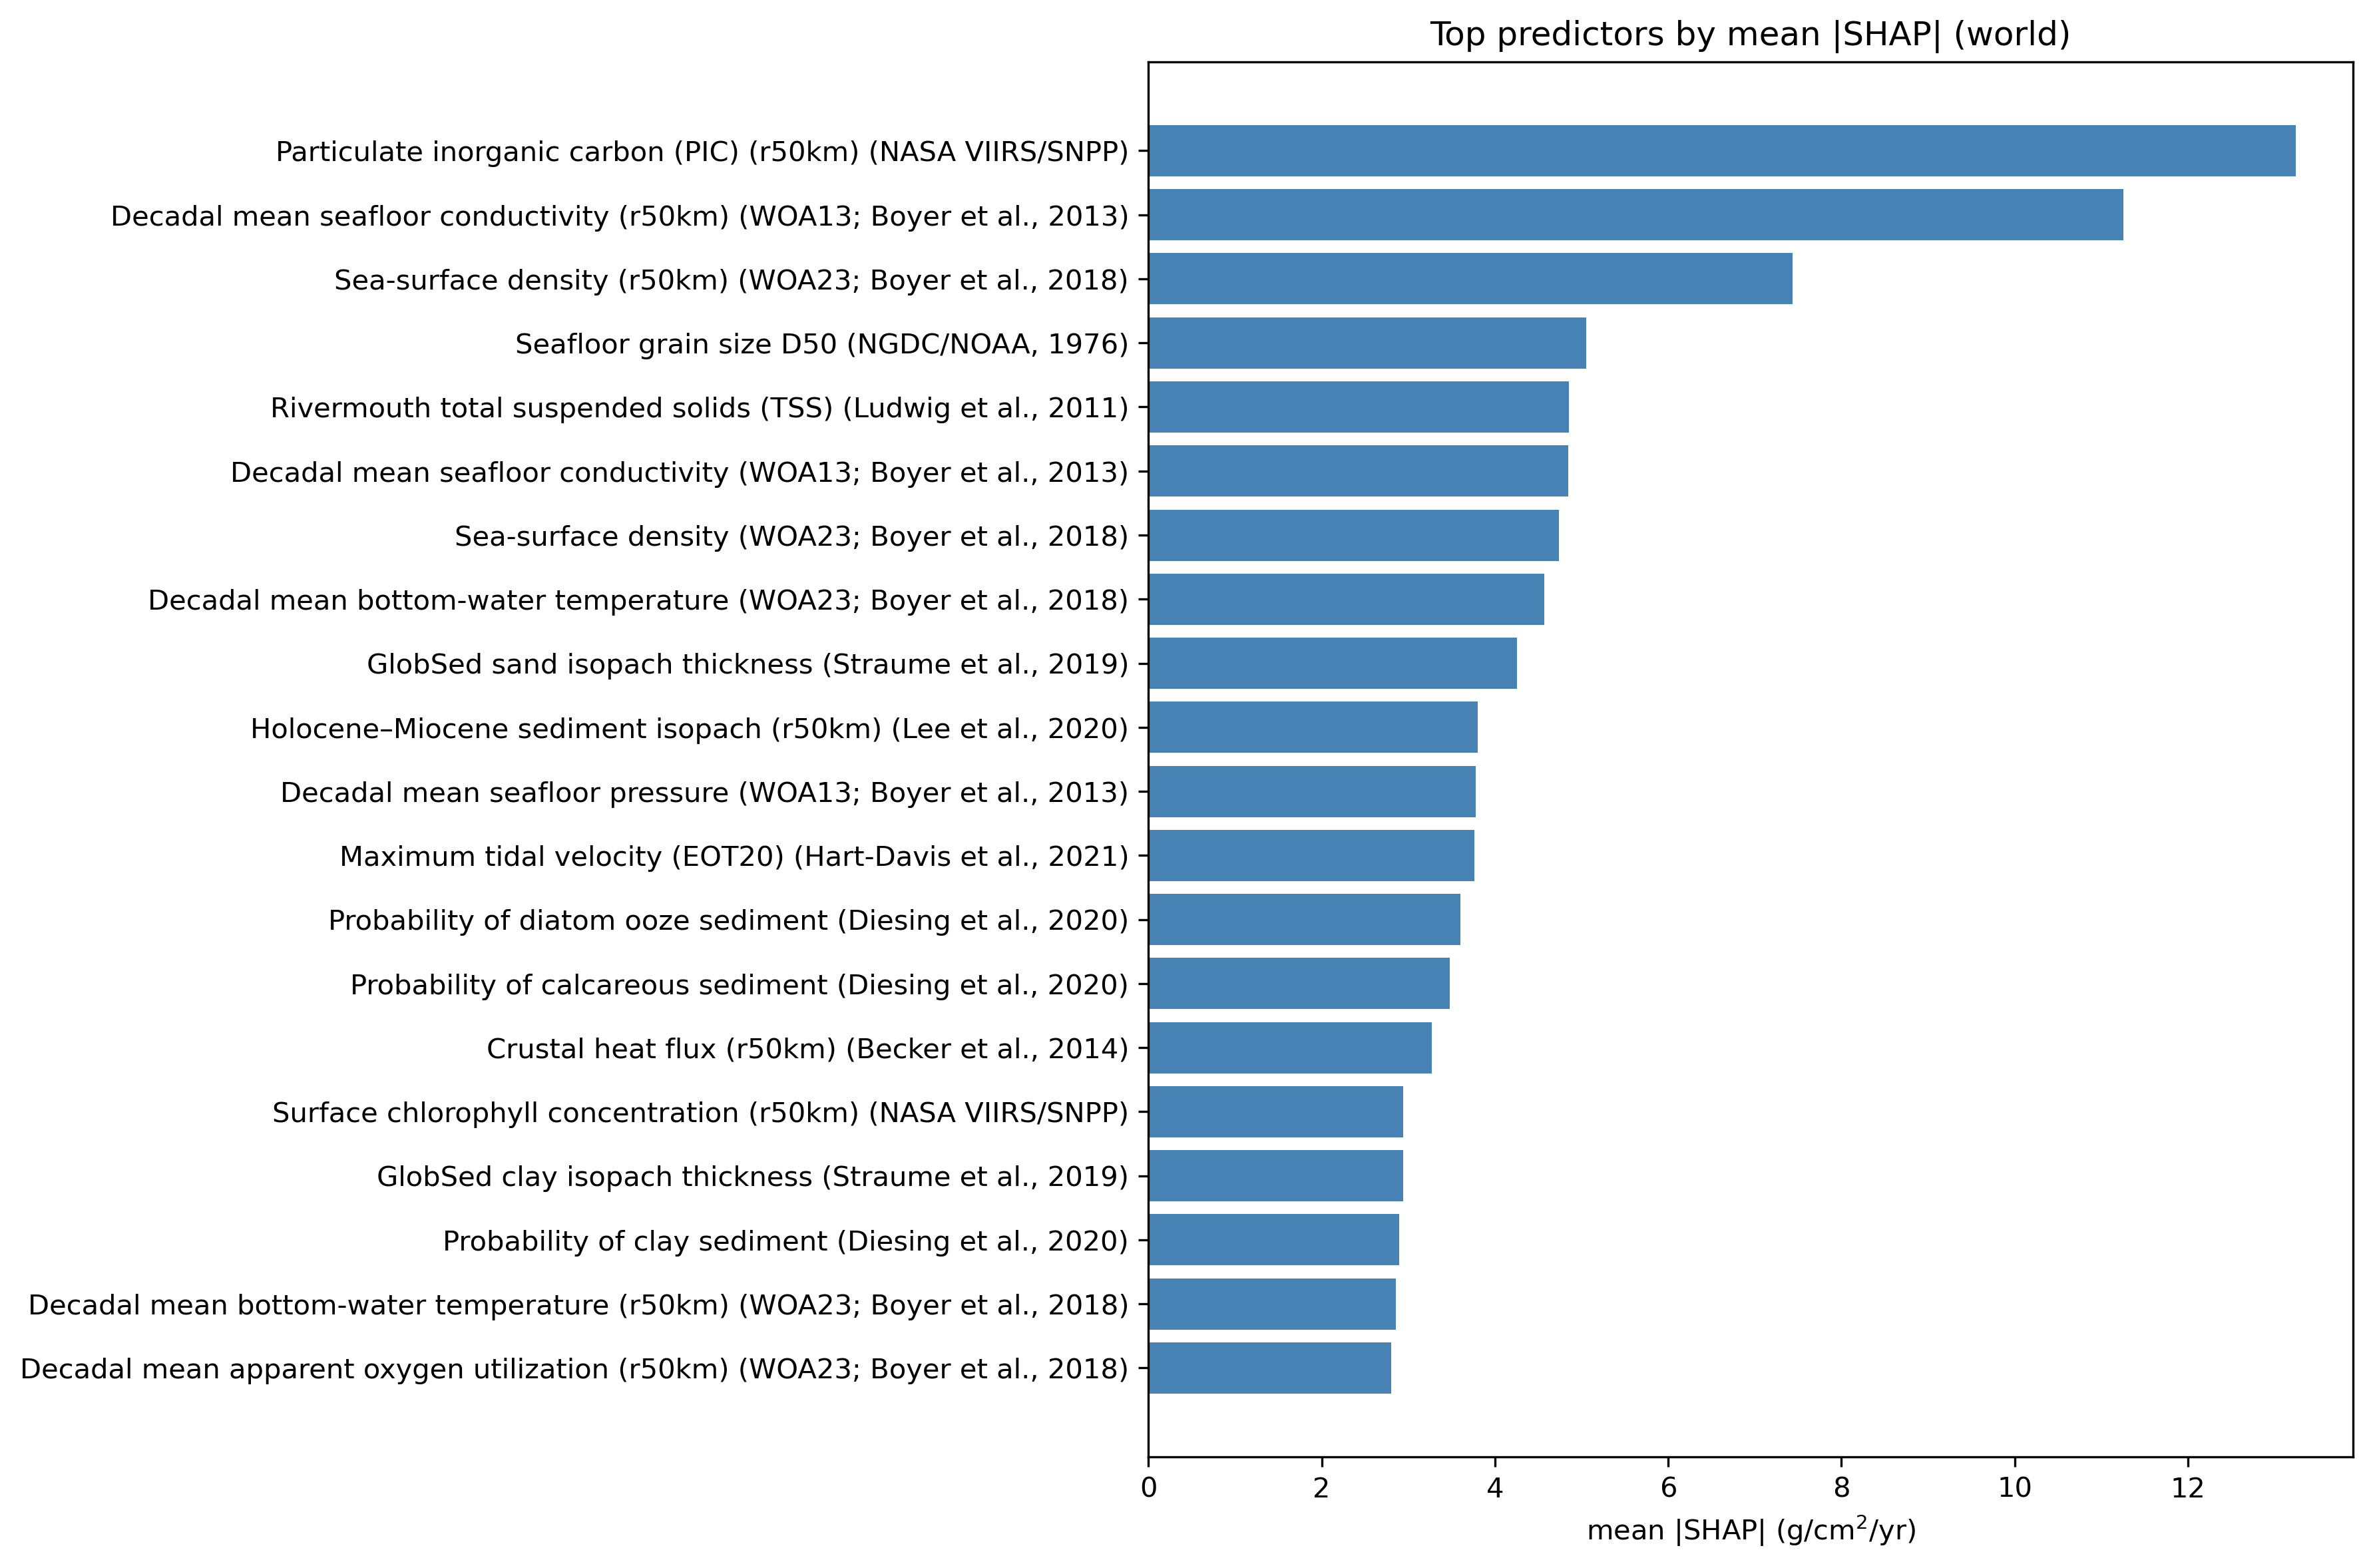

In [6]:
# Compute mean |SHAP| per feature
mean_abs = sum_abs / n_explained
np.save(OUT_DIR / "shap_mean_abs_ocean.npy", mean_abs)
np.save(OUT_DIR / "shap_n_explained_count.npy", np.array([n_explained], dtype=np.int64))
np.save(OUT_DIR / "shap_values_plot_sample.npy", reservoir_shap[:reservoir_filled])
np.save(OUT_DIR / "shap_features_plot_sample.npy", reservoir_feat[:reservoir_filled])

# Feature names
feature_names = [ln.strip() for ln in FEATURE_LIST.read_text().splitlines() if ln.strip()]
if len(feature_names) == N_FEATURES + 1:
    feature_names = feature_names[1:]

# Ranking table
df_rank = pd.DataFrame({
    "feature_name": feature_names,
    "mean_abs_shap": mean_abs,
}).sort_values("mean_abs_shap", ascending=False)
df_rank.to_csv(OUT_DIR / "shap_ranking_predictors.csv", index=False)
print(f"Saved rankings: {OUT_DIR.relative_to(PROJECT_ROOT)}/shap_ranking_predictors.csv")
print("Top 10 by |SHAP|:")
print(df_rank.head(10).to_string(index=False))

# Bar chart
fig, ax = plt.subplots(figsize=(12, 8))
top = df_rank.sort_values("mean_abs_shap", ascending=True).tail(20)
ax.barh(top["feature_name"], top["mean_abs_shap"], color="steelblue")
ax.set_title(f"Top predictors by mean |SHAP| (MTL map{MAP_ID}, nomask / 113-d)")
ax.set_xlabel(r"mean |SHAP| (g/cm$^2$/yr)")
fig.tight_layout()
fig.savefig(OUT_DIR / "shap_ranking_predictors.png", dpi=300, bbox_inches="tight")
plt.show()

# Show the publication beeswarm/ranking figure from notebooks/figs
# (so the notebook preview works without re-running the full SHAP job).
from IPython.display import Image, display
_figs = Path("/gxfs_work/cau/sunms498/work/mtl-mar/notebooks/figs")
_rank = _figs / "shap_ranking_predictors.png"
if _rank.exists():
    display(Image(filename=str(_rank), width=900))
elif (OUT_DIR / "shap_ranking_predictors.png").exists():
    display(Image(filename=str(OUT_DIR / "shap_ranking_predictors.png"), width=900))


## 7. Beeswarm plot

The beeswarm shows each ocean cell as a dot, coloured by the actual feature
value (red = high, blue = low).  The horizontal position is the SHAP value —
how much that feature pushed the prediction away from the baseline.

Saved beeswarm plots under results/shap_MTL_single_nomask_map47_[128,128,128,128]_shared2_world
Done.


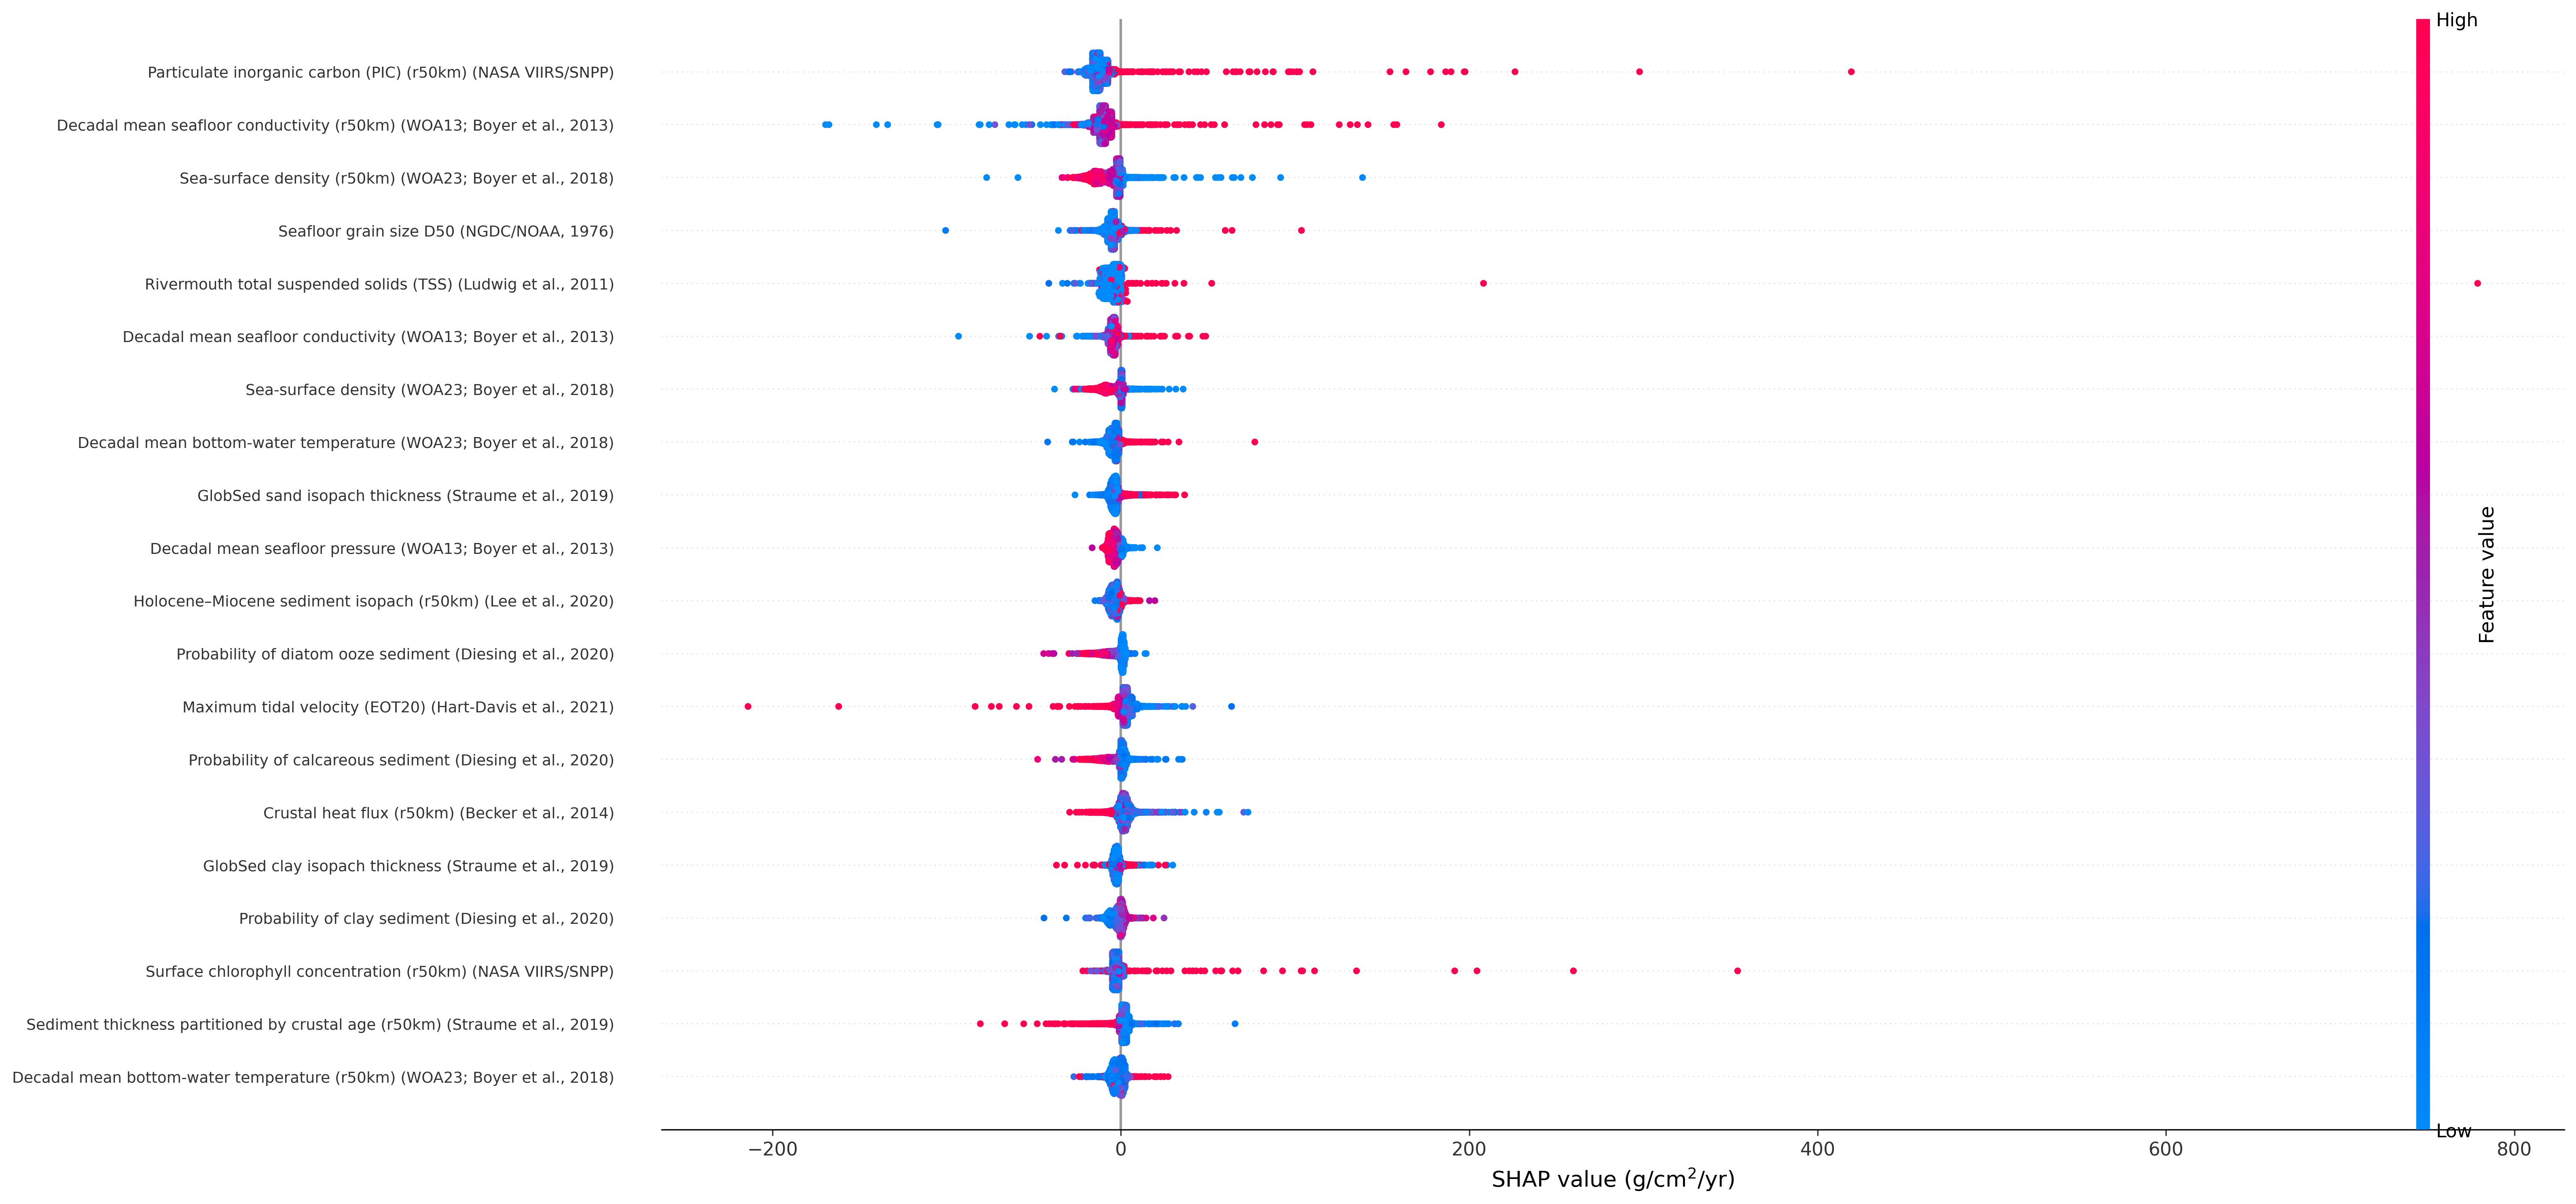

In [14]:
# Publication-quality beeswarm — matches paper Fig. 4a style
import textwrap, sys
sys.path[:0] = [str(Path("/gxfs_work/cau/sunms498/work/nn4sedratetoc/notebooks/SedRate"))]
from shap_feature_display_names import display_names_for_list
from test_shap_beeswarm import shap_summary_plot_with_layout

plot_shap = reservoir_shap[:reservoir_filled]
plot_feat = reservoir_feat[:reservoir_filled]

display_names = [
    "\n".join(textwrap.wrap(n, width=40, break_long_words=False, break_on_hyphens=False))
    for n in display_names_for_list(feature_names)
]

# Paper-style beeswarm with custom layout
shap_summary_plot_with_layout(
    plot_shap,
    pd.DataFrame(plot_feat, columns=display_names),
    feature_names=display_names,
    plot_size=(7.4, 7.0),
    feature_frac=0.42,
    beeswarm_frac=0.40,
    y_labelsize=12,
    dot_size=1.5,
    xlabel=r"SHAP value (g/cm$^2$/yr)",
    save_path=str(OUT_DIR / "shap_summary_channels_beeswarm.png"),
    max_display=10,
)

# Also save default SHAP summary_plot for comparison
plt.figure(dpi=300)
shap.summary_plot(
    plot_shap,
    pd.DataFrame(plot_feat, columns=display_names),
    feature_names=display_names,
    max_display=10,
    show=False,
)
plt.gca().set_xlabel(r"SHAP value (g/cm$^2$/yr)")
plt.gcf().savefig(OUT_DIR / "shap_summary_channels.png", bbox_inches="tight", dpi=300)
plt.show()

print(f"Saved beeswarm plots under {OUT_DIR.relative_to(PROJECT_ROOT)}")

# Display the publication-quality version
from IPython.display import Image, display
display(Image(filename=str(OUT_DIR / "shap_summary_channels_beeswarm.png"), width=700))
print("Done.")

## 8. Continental shelf (CS) and deep ocean (DO) beeswarm plots

The paper figure (Fig. 4) shows three panels: (a) ocean-wide, (b) continental shelves,
and (c) deep ocean. The CS and DO SHAP values were computed on the HPC cluster using
`Sed_MTL_shap_nomask_map47.py --region CS` and `--region DO` respectively.

These cells load the pre-computed SHAP reservoir samples and reproduce the
publication-quality beeswarm plots using `shap_summary_plot_with_layout`.

In [15]:
import textwrap
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
import sys

# Project paths
PROJECT_ROOT = Path("/gxfs_work/cau/sunms498/work/nn4sedratetoc")
sys.path[:0] = [str(PROJECT_ROOT / "notebooks" / "SedRate")]
from shap_feature_display_names import display_names_for_list
from test_shap_beeswarm import shap_summary_plot_with_layout

SHAP_XLABEL = r"SHAP value (g/cm$^2$/yr)"

# Pre-computed SHAP results (from HPC cluster runs)
RESULTS_BASE = PROJECT_ROOT / "to_delete" / "results_20261005"
SHAP_DIRS = {
    "ocean": RESULTS_BASE / "shap_MTL_single_nomask_map47_[128,128,128,128]_shared2_world",
    "CS":    RESULTS_BASE / "shap_MTL_single_nomask_map47_[128,128,128,128]_shared2_world_CS",
    "DO":    RESULTS_BASE / "shap_MTL_single_nomask_map47_[128,128,128,128]_shared2_world_DO",
}

# Feature names
FEATURE_LIST = PROJECT_ROOT / "data/interim/selectedFeatureLists/selectedfeatures_v_men.txt"
feature_names = [ln.strip() for ln in FEATURE_LIST.read_text().splitlines() if ln.strip()]
if len(feature_names) == 114:  # header line
    feature_names = feature_names[1:]

display_names = [
    "\n".join(textwrap.wrap(n, width=40, break_long_words=False, break_on_hyphens=False))
    for n in display_names_for_list(feature_names)
]

# Verify all directories exist
for region, d in SHAP_DIRS.items():
    assert d.exists(), f"Missing SHAP dir: {d}"
    print(f"{region:6s}: {d.name}")

ocean : shap_MTL_single_nomask_map47_[128,128,128,128]_shared2_worldCS    : shap_MTL_single_nomask_map47_[128,128,128,128]_shared2_world_CSDO    : shap_MTL_single_nomask_map47_[128,128,128,128]_shared2_world_DO

Ocean: 5,000 sample cells, 113 features(a) Ocean-wide

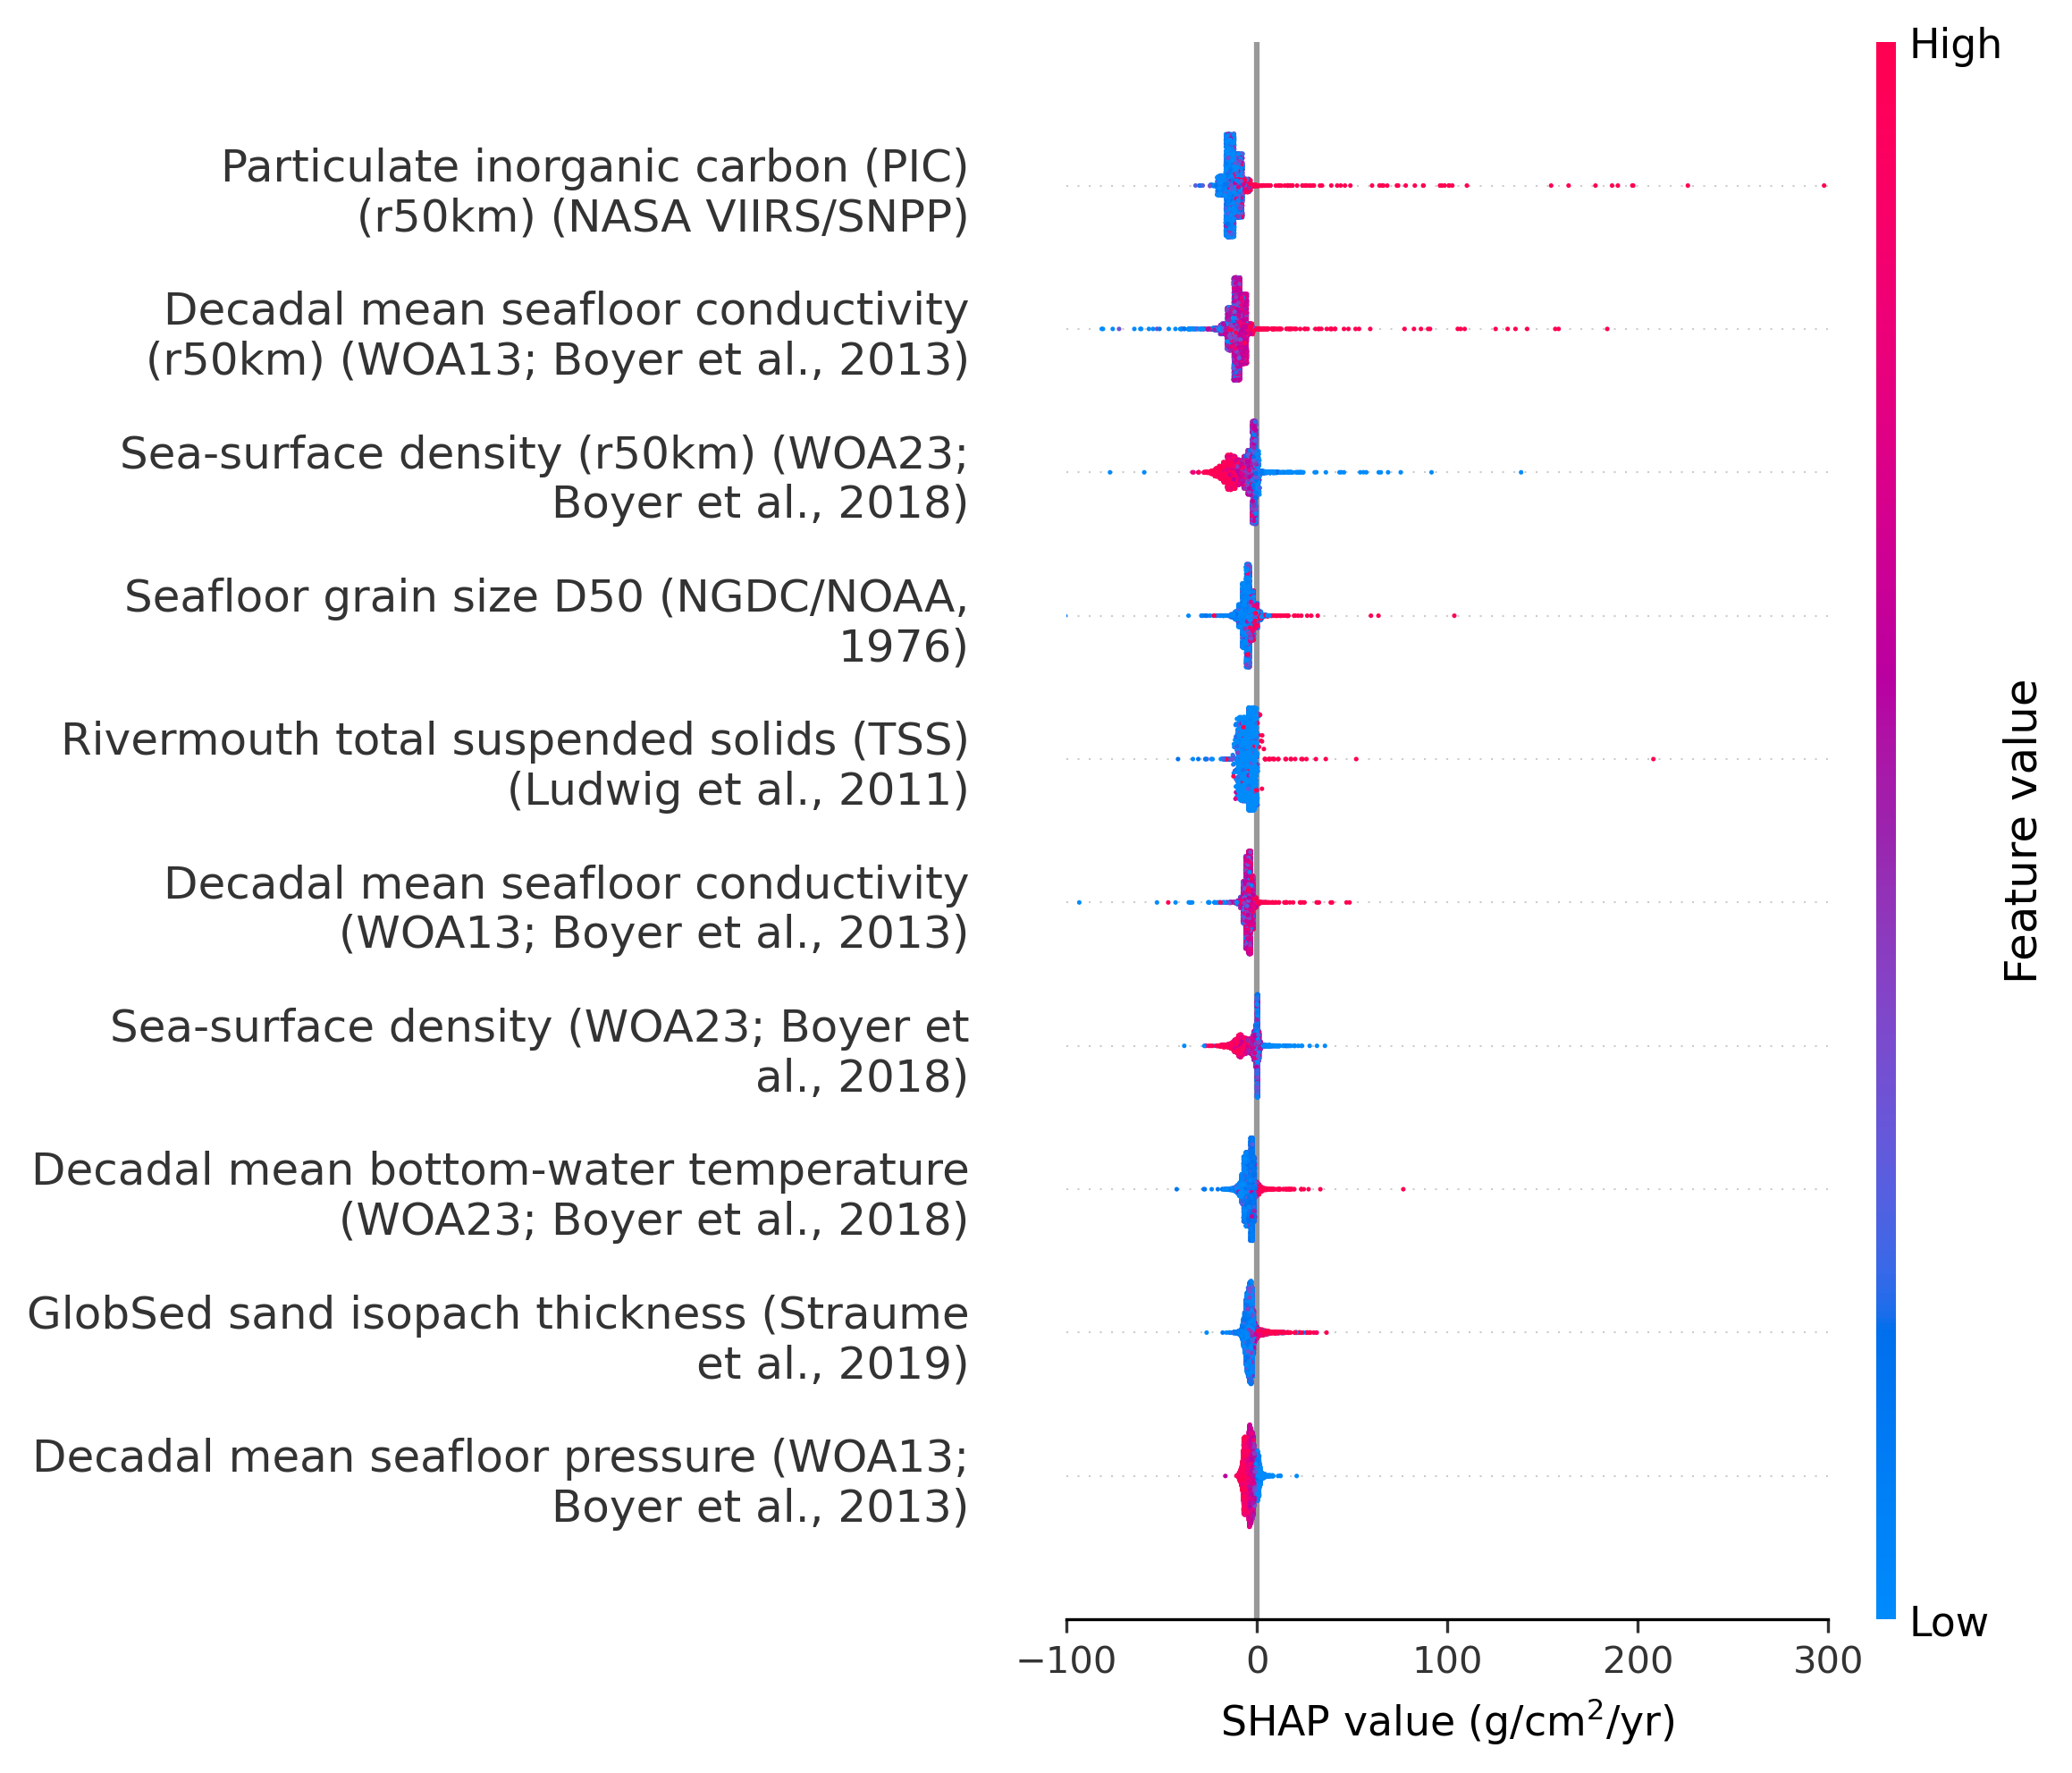

In [16]:
# (a) Ocean-wide beeswarm — matches paper Fig. 4a
shap_vals = np.load(SHAP_DIRS["ocean"] / "shap_values_plot_sample.npy")
feat_vals = np.load(SHAP_DIRS["ocean"] / "shap_features_plot_sample.npy")
print(f"Ocean: {shap_vals.shape[0]:,} sample cells, {shap_vals.shape[1]} features")

out_dir = Path("figs")
out_dir.mkdir(exist_ok=True)

shap_summary_plot_with_layout(
    shap_vals,
    pd.DataFrame(feat_vals, columns=display_names),
    feature_names=display_names,
    plot_size=(7.4, 7.0),
    feature_frac=0.42,
    beeswarm_frac=0.40,
    y_labelsize=12,
    dot_size=1.5,
    xlabel=SHAP_XLABEL,
    save_path=str(out_dir / "shap_values_entire_new.png"),
    max_display=10,
)
from IPython.display import Image, display
print("(a) Ocean-wide")
display(Image(filename=str(out_dir / "shap_values_entire_new.png"), width=700))

CS: 5,000 sample cells, 113 features(b) Continental shelves

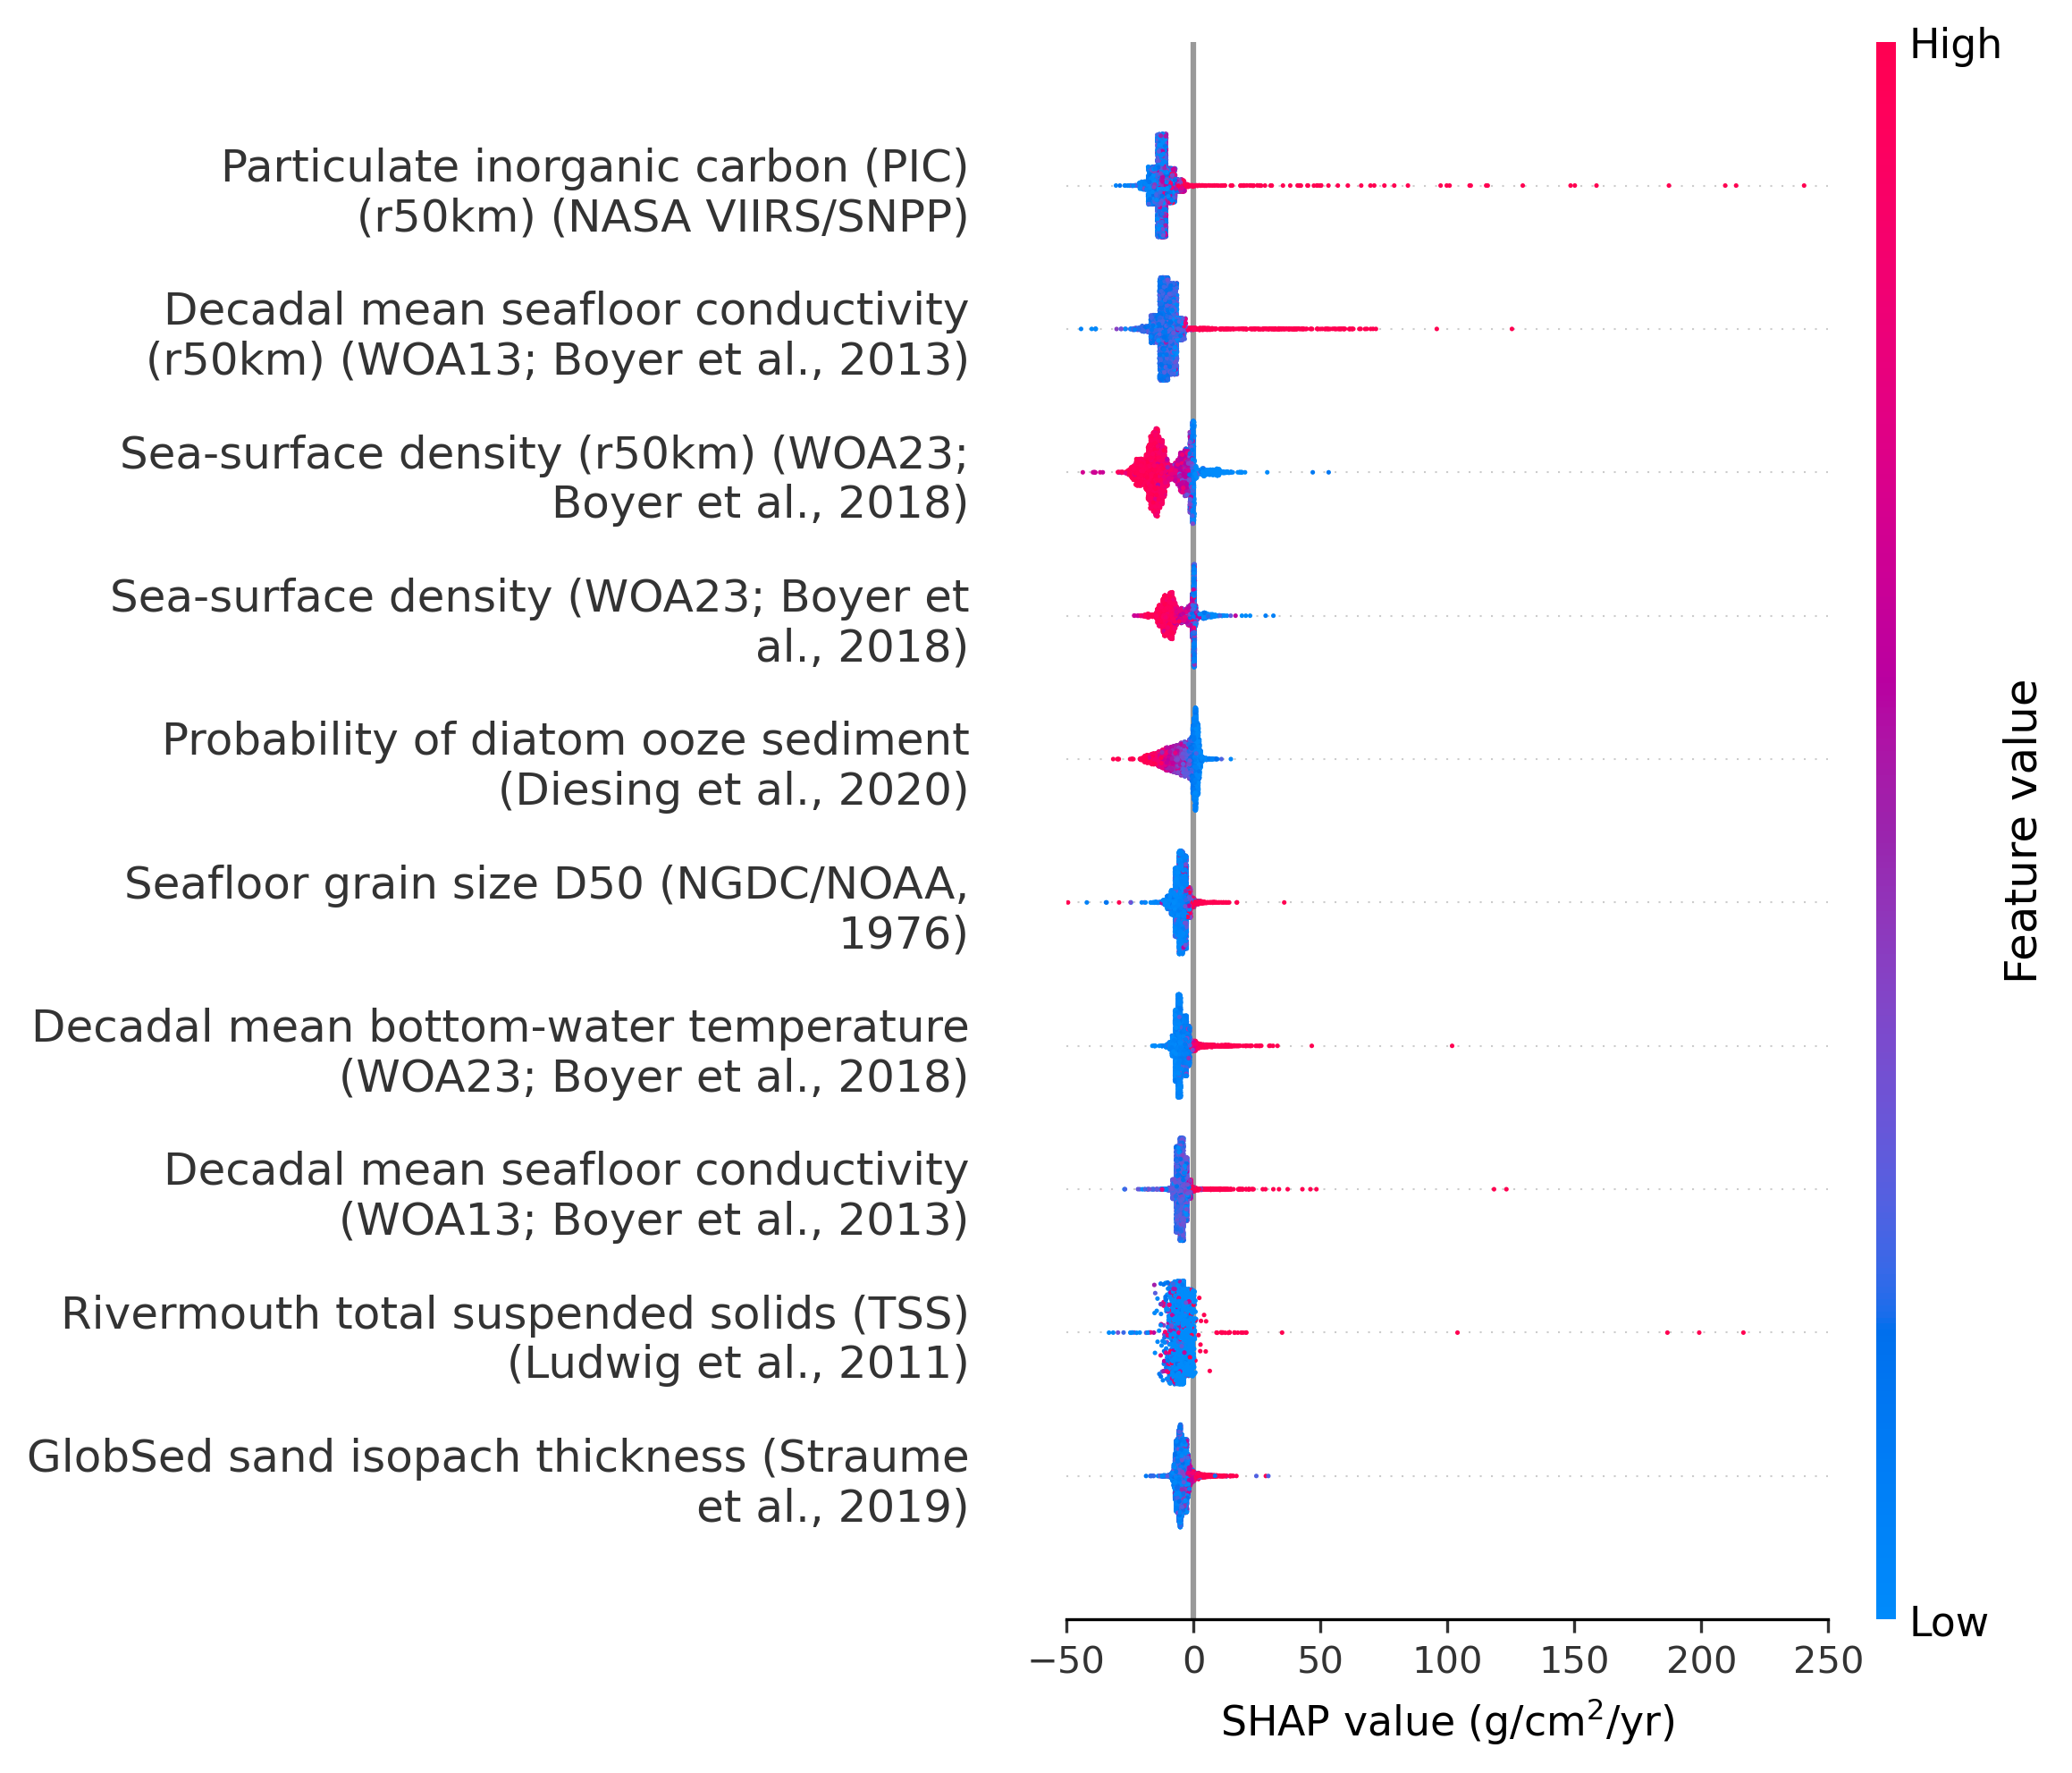

In [17]:
# (b) Continental shelves beeswarm — matches paper Fig. 4b
shap_vals_cs = np.load(SHAP_DIRS["CS"] / "shap_values_plot_sample.npy")
feat_vals_cs = np.load(SHAP_DIRS["CS"] / "shap_features_plot_sample.npy")
print(f"CS: {shap_vals_cs.shape[0]:,} sample cells, {shap_vals_cs.shape[1]} features")

shap_summary_plot_with_layout(
    shap_vals_cs,
    pd.DataFrame(feat_vals_cs, columns=display_names),
    feature_names=display_names,
    plot_size=(7.4, 7.0),
    feature_frac=0.42,
    beeswarm_frac=0.40,
    y_labelsize=12,
    dot_size=1.5,
    xlabel=SHAP_XLABEL,
    save_path=str(out_dir / "shap_values_CS_new.png"),
    max_display=10,
)
print("(b) Continental shelves")
display(Image(filename=str(out_dir / "shap_values_CS_new.png"), width=700))

DO: 5,000 sample cells, 113 features(c) Deep ocean

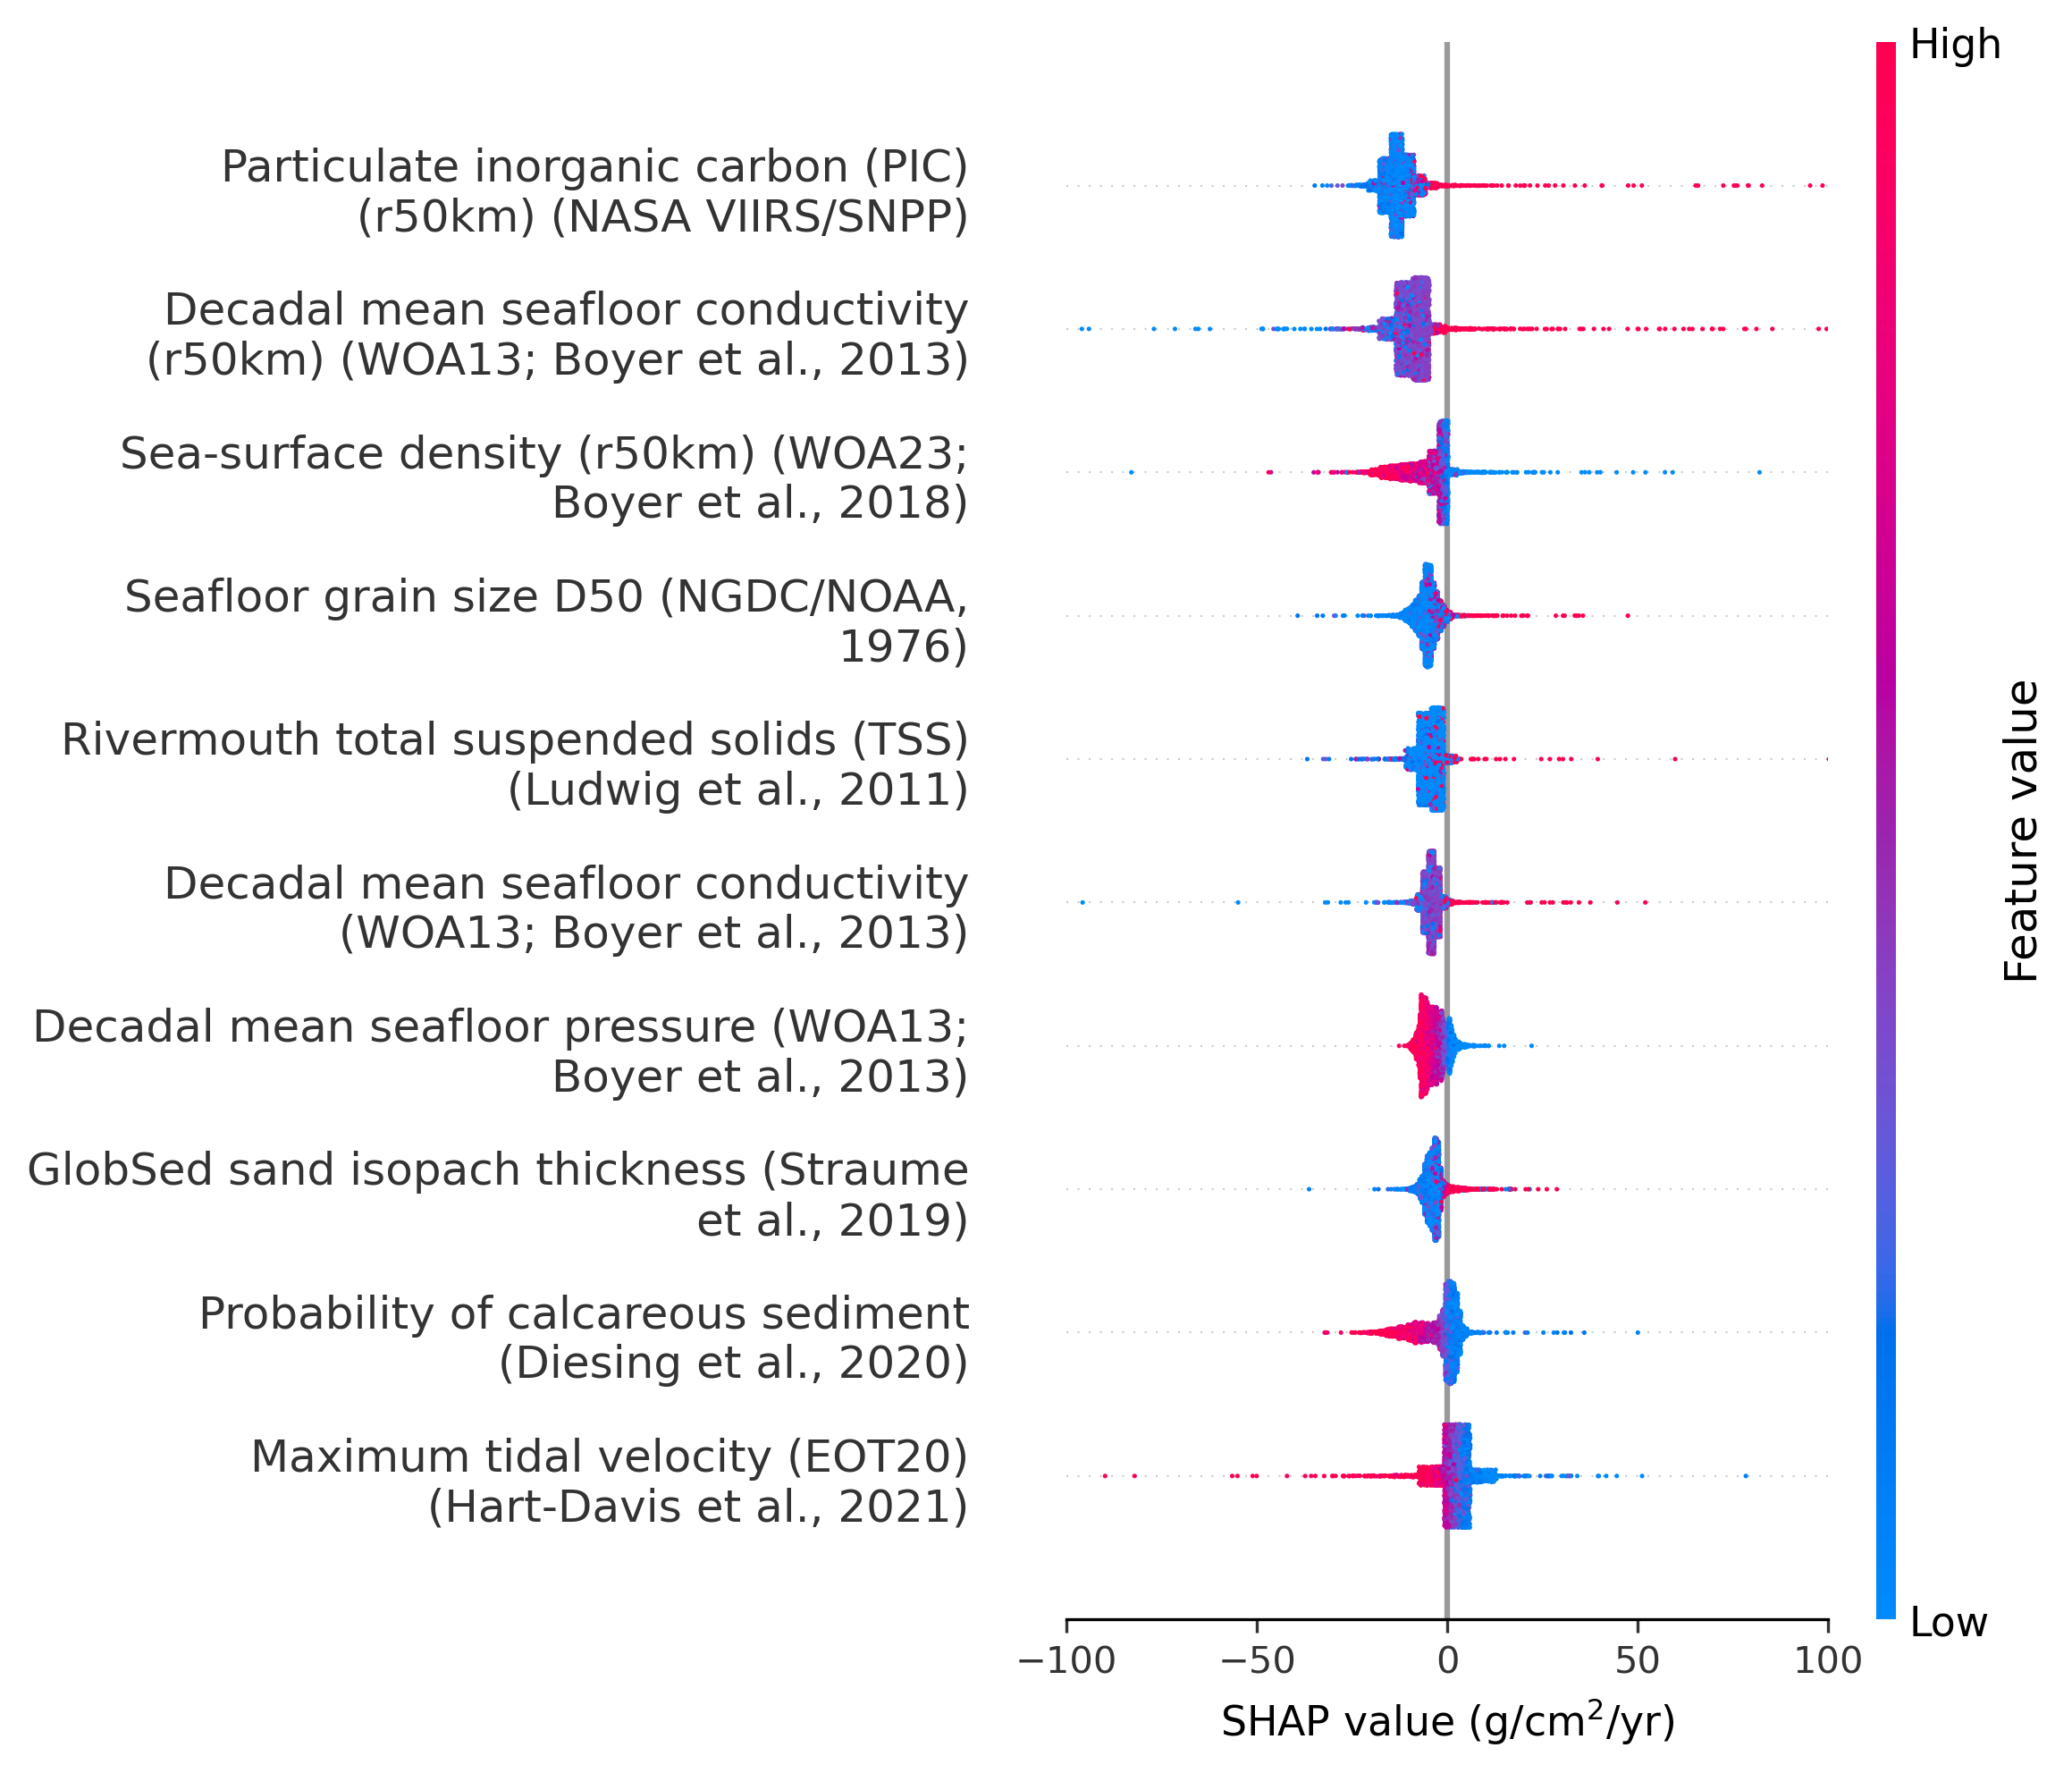

In [18]:
# (c) Deep ocean beeswarm — matches paper Fig. 4c
shap_vals_do = np.load(SHAP_DIRS["DO"] / "shap_values_plot_sample.npy")
feat_vals_do = np.load(SHAP_DIRS["DO"] / "shap_features_plot_sample.npy")
print(f"DO: {shap_vals_do.shape[0]:,} sample cells, {shap_vals_do.shape[1]} features")

shap_summary_plot_with_layout(
    shap_vals_do,
    pd.DataFrame(feat_vals_do, columns=display_names),
    feature_names=display_names,
    plot_size=(7.4, 7.0),
    feature_frac=0.42,
    beeswarm_frac=0.40,
    y_labelsize=12,
    dot_size=1.5,
    xlabel=SHAP_XLABEL,
    save_path=str(out_dir / "shap_values_DO_new.png"),
    max_display=10,
)
print("(c) Deep ocean")
display(Image(filename=str(out_dir / "shap_values_DO_new.png"), width=700))

In [19]:
# Feature ranking comparison CS vs DO
mean_abs_ocean = np.load(SHAP_DIRS["ocean"] / "shap_mean_abs_ocean.npy")
mean_abs_cs    = np.load(SHAP_DIRS["CS"]    / "shap_mean_abs_ocean.npy")
mean_abs_do    = np.load(SHAP_DIRS["DO"]    / "shap_mean_abs_ocean.npy")

clean_names = display_names_for_list(feature_names)
df = pd.DataFrame({
    "feature": clean_names,
    "|SHAP| ocean": mean_abs_ocean,
    "|SHAP| CS": mean_abs_cs,
    "|SHAP| DO": mean_abs_do,
})
df["rank_ocean"] = df["|SHAP| ocean"].rank(ascending=False).astype(int)
df["rank_CS"]    = df["|SHAP| CS"].rank(ascending=False).astype(int)
df["rank_DO"]    = df["|SHAP| DO"].rank(ascending=False).astype(int)
df = df.sort_values("|SHAP| ocean", ascending=False)

print("Top 15 features by mean |SHAP|:")
print(df.head(15)[["feature", "|SHAP| ocean", "rank_ocean", "|SHAP| CS", "rank_CS", "|SHAP| DO", "rank_DO"]].to_string(index=False))

print(f"\nDone — all three beeswarm panels saved to {out_dir}/")

Top 15 features by mean |SHAP|:                                                               feature  |SHAP| ocean  rank_ocean  |SHAP| CS  rank_CS  |SHAP| DO  rank_DO          Particulate inorganic carbon (PIC) (r50km) (NASA VIIRS/SNPP)     13.243539           1  12.950554        1  13.845205        1Decadal mean seafloor conductivity (r50km) (WOA13; Boyer et al., 2013)     11.251094           2  11.280959        2  10.794738        2               Sea-surface density (r50km) (WOA23; Boyer et al., 2018)      7.438991           3  10.449737        3   5.495391        3                             Seafloor grain size D50 (NGDC/NOAA, 1976)      5.050564           4   5.113474        5   5.461282        4         Rivermouth total suspended solids (TSS) (Ludwig et al., 2011)      4.851903           5   4.907860        9   4.875448        5        Decadal mean seafloor conductivity (WOA13; Boyer et al., 2013)      4.842772           6   4.987692        7   4.601382        6                 